# 04 · Exploratory data analysis

**Objective:** understand when and where published bus demand and scheduled service differ,
then identify evidence-based questions for planners. This is a historical Manhattan bus study,
with broader New York demand retained as context.

The analysis covers temporal demand patterns, route profiles, hourly service comparisons,
geographic density and route overlap. Low descriptive service-use ratios identify candidates
for review; they do not establish inefficiency. Occupancy, delay and causal benefits are
not observed in these sources.

Run after notebooks 01–03. Every chart uses saved, fingerprinted products, identifies its population
and period, and is exported for sharing. No model or dashboard is built in this stage.

In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display

ROOT=next(p for p in [Path.cwd(),*Path.cwd().parents] if (p/'scripts/collect_new_york.py').exists())
OUT=ROOT/'data/processed/new_york'
REPORT=ROOT/'reports/eda'
FIGURES=REPORT/'figures'
FIGURES.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_columns',None)
pd.set_option('display.max_rows',100)
plt.rcParams.update({'figure.figsize':(11,5),'figure.dpi':110,'axes.spines.top':False,
    'axes.spines.right':False,'axes.grid':True,'grid.alpha':0.18,'font.size':10})
def finish(name):
    plt.tight_layout()
    plt.savefig(FIGURES/f'{name}.png',dpi=180,bbox_inches='tight')
    plt.show()
    plt.close()
manifest=json.loads((OUT/'feature_manifest.json').read_text())
for name,item in manifest['products'].items():
    assert hashlib.sha256((OUT/f'{name}.csv').read_bytes()).hexdigest()==item['sha256']
print('All feature-product fingerprints verified. Figures will be exported to reports/eda/figures.')

All feature-product fingerprints verified. Figures will be exported to reports/eda/figures.


## 1. What population can each question use?

Separate full-history demand from historically aligned service comparisons. A collection's largest
row count is not the effective sample size of every analysis. Daily rows are repeated observations
on the same routes, and source estimates may include publisher imputation.

In [2]:
daily=pd.read_csv(OUT/'daily_demand_features.csv',dtype={'bus_route':'string'},parse_dates=['payment_date'])
matched=pd.read_csv(OUT/'matched_daily_features.csv',dtype={'bus_route':'string',
    'schedule_comparison_eligible':'boolean','dst_context_review':'boolean',
    'block_overlap_review':'boolean','partial_calendar_review':'boolean',
    'comparison_eligible':'boolean','source_snapshot':'string','prior_source_snapshot':'string'},parse_dates=['payment_date'])
hours=pd.read_csv(OUT/'matched_hourly_features.csv',dtype={'bus_route':'string'},parse_dates=['payment_date','local_hour'])
profiles=pd.read_csv(OUT/'route_day_type_profiles.csv',dtype={'bus_route':'string'})
structure=pd.read_csv(OUT/'route_structure.csv',dtype={'bus_route':'string'})
overlap=pd.read_csv(OUT/'route_overlap.csv',dtype={'route_a':'string','route_b':'string'})
stops=pd.read_csv(OUT/'map_stops.csv',dtype={'stop_id':'string'})
shapes=pd.read_csv(OUT/'map_shapes.csv',dtype={'shape_id':'string'})
route_shapes=pd.read_csv(OUT/'map_route_shapes.csv',dtype={'bus_route':'string','shape_id':'string'})
pilot_routes=sorted(structure.bus_route.unique())
pilot=daily.loc[daily.bus_route.isin(pilot_routes)].copy()
eligible=matched.loc[matched.comparison_eligible & matched.scheduled_departures.gt(0) & matched.scheduled_service_hours.gt(0)].copy()
coverage=pd.DataFrame([
    [name,len(frame),frame.bus_route.nunique(),frame.payment_date.nunique(),frame.payment_date.min(),frame.payment_date.max()]
    for name,frame in [('All collected daily demand',daily),('Manhattan daily demand',pilot),
                       ('Manhattan comparable demand/service',eligible),('Manhattan hourly pilot',hours)]
],columns=['population','rows','route_codes','dates','first_date','last_date'])
display(coverage)
coverage.to_csv(REPORT/'analysis_coverage.csv',index=False)

,population,rows,route_codes,dates,first_date,last_date
0,All collected daily demand,275896,450,638,2025-01-01,2026-09-30
1,Manhattan daily demand,26158,41,638,2025-01-01,2026-09-30
2,Manhattan comparable demand/service,10014,41,246,2026-01-05,2026-09-30
3,Manhattan hourly pilot,90528,41,92,2026-07-01,2026-09-30


## 2. Where does comparability get lost?

The stages below are sequential row counts, not interchangeable denominators. Missing archives,
future-effective captures, overnight context gaps, DST review and block conflicts are retained
as evidence rather than hidden by falling back to another timetable.

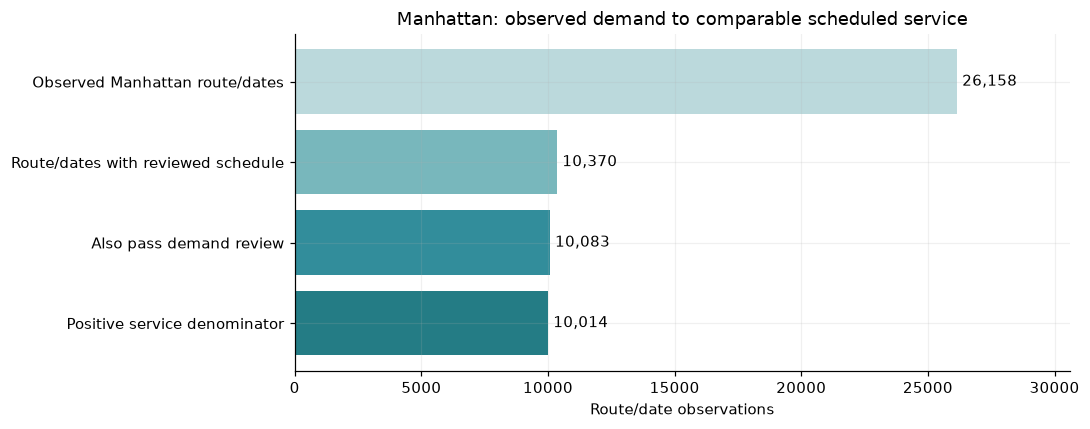

,rows
Observed Manhattan route/dates,26158
Route/dates with reviewed schedule,10370
Also pass demand review,10083
Positive service denominator,10014


Missing schedules remain unavailable; they are never filled from a later or older timetable.


In [3]:
stages=pd.Series({'Observed Manhattan route/dates':len(matched),
    'Route/dates with reviewed schedule':int(matched.schedule_comparison_eligible.astype('boolean').fillna(False).sum()),
    'Also pass demand review':int(matched.comparison_eligible.sum()),
    'Positive service denominator':len(eligible)})
fig,ax=plt.subplots(figsize=(10,4))
ax.barh(stages.index[::-1],stages.values[::-1],color=['#247c85','#328d9b','#78b7bc','#bbd9dc'])
for i,value in enumerate(stages.values[::-1]): ax.text(value,i,f' {value:,}',va='center')
ax.set(xlabel='Route/date observations',title='Manhattan: observed demand to comparable scheduled service')
ax.set_xlim(0,stages.max()*1.17)
finish('01_comparison_coverage')
display(stages.rename('rows').to_frame())
print('Missing schedules remain unavailable; they are never filled from a later or older timetable.')

## 3. Demand over time: source values and conservative view

Use a fixed set of the 41 historically referenced route codes. An all-zero/low network flag is
a review signal, not proof of an outage. Showing both curves makes the masking decision visible.
Totals require all 41 route observations; absence is not interpreted as zero.

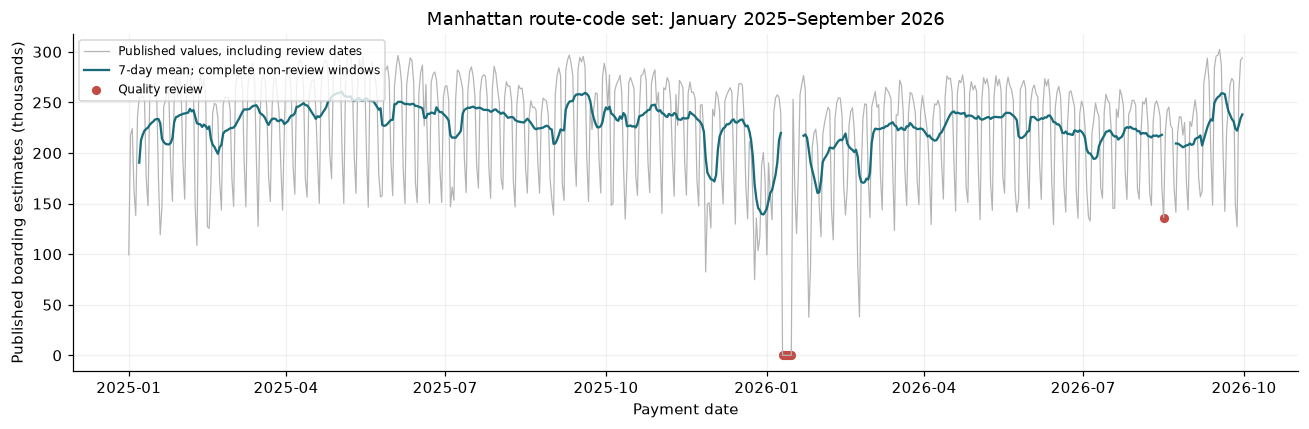

,published_boardings,analysis_boardings,routes_reported,review
payment_date,,,,
2026-01-10,0,NaN,41,True
2026-01-11,0,NaN,41,True
2026-01-12,0,NaN,41,True
2026-01-13,0,NaN,41,True
2026-01-14,0,NaN,41,True
2026-01-15,0,NaN,41,True
2026-08-16,136125,NaN,41,True


Interpretation: the unexplained low periods are visible in the raw source and excluded only from the conservative view.


In [4]:
network=pilot.groupby('payment_date').agg(
    published_boardings=('published_boardings',lambda s:s.sum(min_count=len(pilot_routes))),
    analysis_boardings=('analysis_boardings',lambda s:s.sum(min_count=len(pilot_routes))),
    routes_reported=('bus_route','nunique'),review=('demand_review_required','any'))
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(network.index,network.published_boardings/1000,color='#b4b4b4',lw=0.8,label='Published values, including review dates')
ax.plot(network.index,network.analysis_boardings.rolling(7,min_periods=7).mean()/1000,color='#176b7a',label='7-day mean; complete non-review windows')
flagged=network.loc[network.review]
ax.scatter(flagged.index,flagged.published_boardings/1000,color='#c34b46',s=25,label='Quality review')
ax.set(title='Manhattan route-code set: January 2025–September 2026',ylabel='Published boarding estimates (thousands)',xlabel='Payment date')
ax.legend(loc='upper left',fontsize=8)
finish('02_daily_demand_history')
display(network.loc[network.review])
print('Interpretation: the unexplained low periods are visible in the raw source and excluded only from the conservative view.')

## 4. Weekday and seasonal patterns

Use mean daily totals within each month/day type, rather than confusing month length with demand.
Weekday is not holiday-adjusted. Differences are descriptive and can reflect holidays, service,
fares, reporting changes or other unobserved factors.

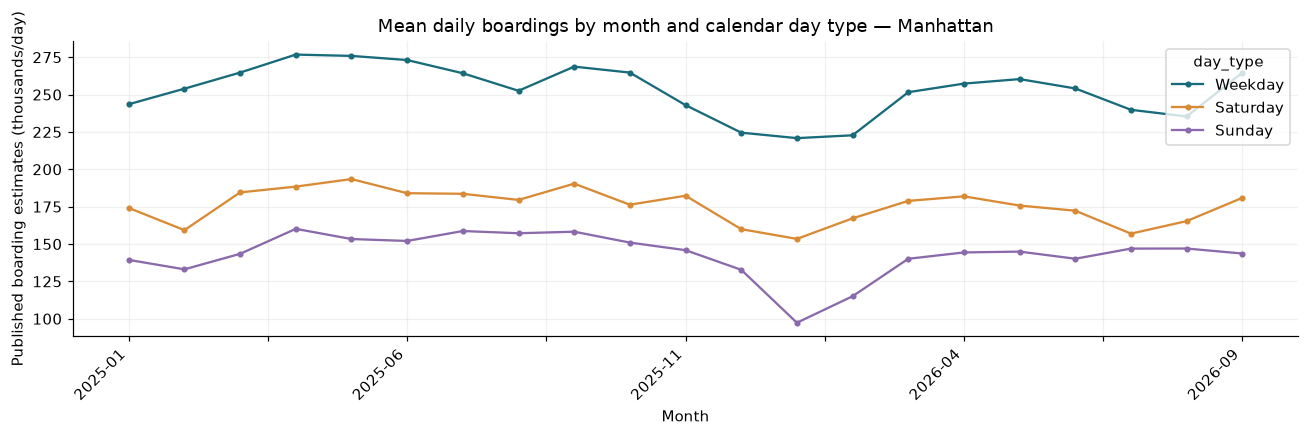

,month,day_type,mean_daily_boardings,included_dates,published_dates
54,2026-07,Saturday,156962.750000,4,4
55,2026-07,Sunday,146950.250000,4,4
56,2026-07,Weekday,239832.217391,23,23
57,2026-08,Saturday,165343.400000,5,5
58,2026-08,Sunday,146992.250000,4,5
59,2026-08,Weekday,235361.142857,21,21
60,2026-09,Saturday,180928.500000,4,4
61,2026-09,Sunday,143656.750000,4,4
62,2026-09,Weekday,264659.681818,22,22


In [5]:
network['month']=network.index.to_period('M').astype(str)
network['day_type']=np.select([network.index.dayofweek==5,network.index.dayofweek==6],['Saturday','Sunday'],default='Weekday')
monthly=network.groupby(['month','day_type']).agg(mean_daily_boardings=('analysis_boardings','mean'),
    included_dates=('analysis_boardings','count'),published_dates=('published_boardings','count')).reset_index()
plot=monthly.pivot(index='month',columns='day_type',values='mean_daily_boardings')/1000
plot[['Weekday','Saturday','Sunday']].plot(marker='o',markersize=3,color=['#176b7a','#d98a35','#8a6aab'],figsize=(12,4))
plt.title('Mean daily boardings by month and calendar day type — Manhattan')
plt.ylabel('Published boarding estimates (thousands/day)');plt.xlabel('Month')
plt.xticks(rotation=45,ha='right')
finish('03_monthly_day_type_trends')
display(monthly.tail(9))
monthly.to_csv(REPORT/'monthly_day_type_demand.csv',index=False)

## 5. Which hours carry the most observed demand?

Hourly observations cover July–September 2026 only. Sum the same 41 route codes for each hour,
then show the median across dates and the interquartile range. The band describes variation
between dates, not prediction uncertainty. No daily ridership is redistributed into invented hours.

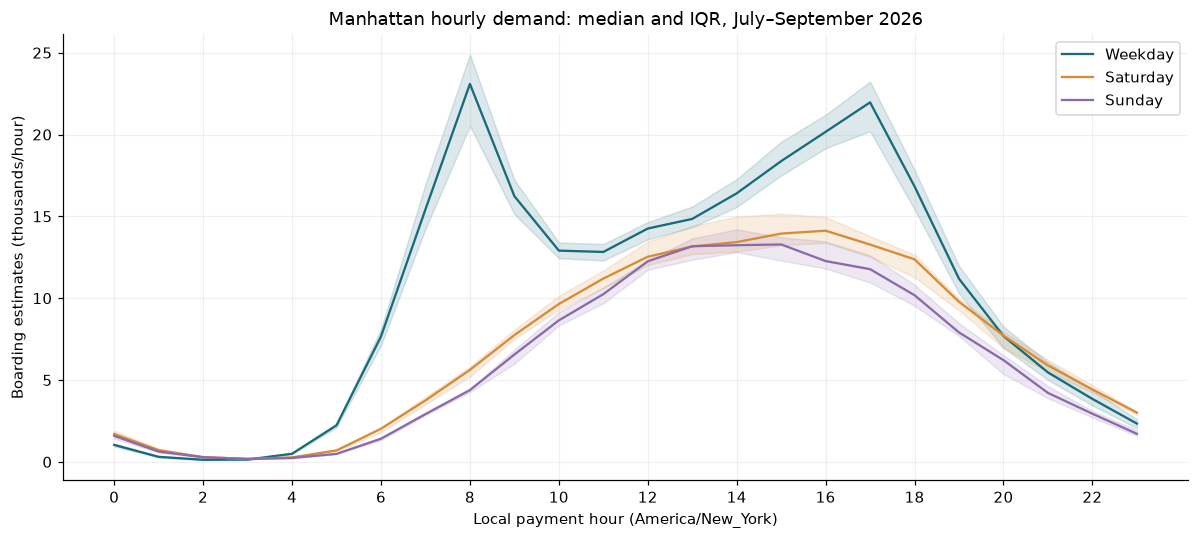

,day_type,hour,median,q25,q75,dates
16,Saturday,16,14125.0,13386.0,14962.00,13
39,Sunday,15,13284.0,12299.0,13728.00,13
56,Weekday,8,23092.0,20534.5,24892.25,66


Peak hours describe boarding demand, not observed crowding or traffic delay.


In [6]:
hour_network=hours.groupby(['payment_date','day_type','hour'],as_index=False).agg(
    boardings=('analysis_boardings',lambda s:s.sum(min_count=len(pilot_routes))))
curves=hour_network.groupby(['day_type','hour']).boardings.agg(
    median='median',q25=lambda s:s.quantile(.25),q75=lambda s:s.quantile(.75),dates='count').reset_index()
fig,ax=plt.subplots()
for day_type,color in [('Weekday','#176b7a'),('Saturday','#d98a35'),('Sunday','#8a6aab')]:
    part=curves.loc[curves.day_type.eq(day_type)]
    ax.plot(part.hour,part['median']/1000,label=day_type,color=color)
    ax.fill_between(part.hour,part.q25/1000,part.q75/1000,color=color,alpha=.15)
ax.set(xticks=range(0,24,2),xlabel='Local payment hour (America/New_York)',ylabel='Boarding estimates (thousands/hour)',
       title='Manhattan hourly demand: median and IQR, July–September 2026')
ax.legend();finish('04_hourly_ridership_curves')
peaks=curves.loc[curves.groupby('day_type')['median'].idxmax()]
display(peaks[['day_type','hour','median','q25','q75','dates']])
print('Peak hours describe boarding demand, not observed crowding or traffic delay.')

## 6. Do all routes peak at the same time?

Compare route/hour profiles in original boarding units and as shares of each route's mean day.
The share plot gives smaller routes equal visual weight without claiming equal absolute demand.

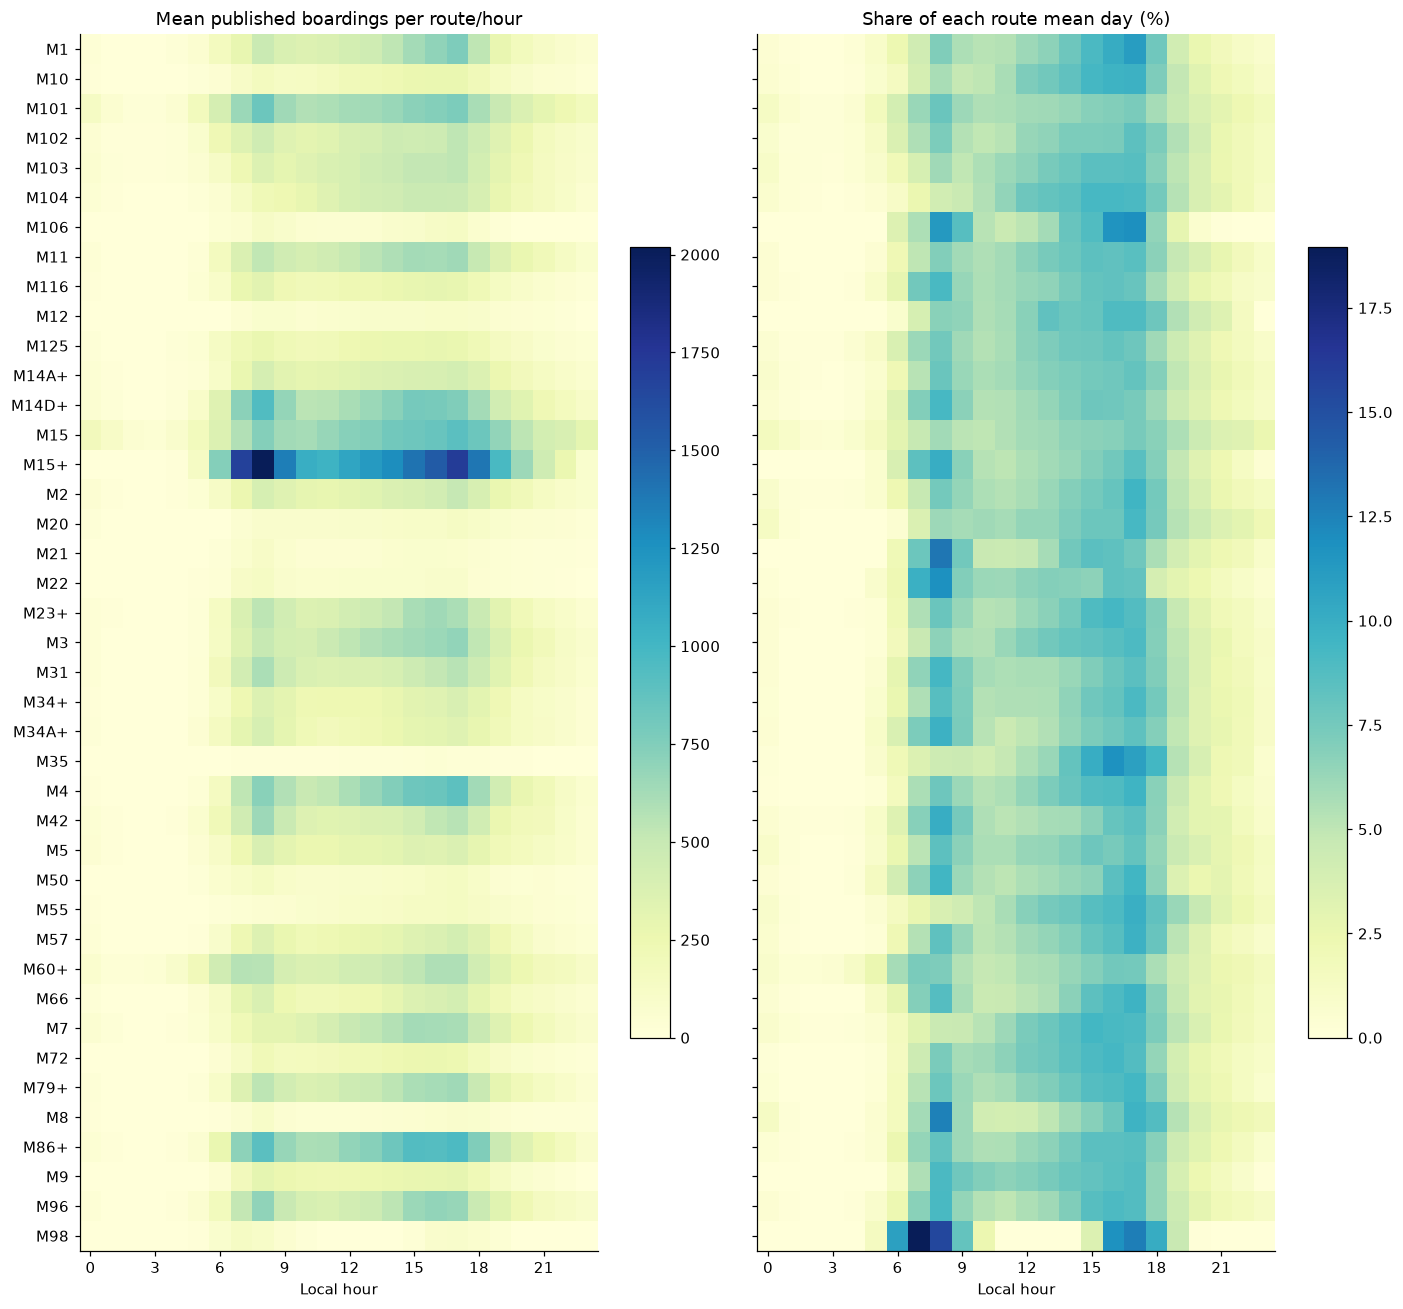

Route/hour samples range: 91 to 92 dates


,sum_of_hourly_means
bus_route,
M15+,20079.277711
M15,12299.446130
M86+,11016.668657
M101,10519.815934
M14D+,10206.329431


In [7]:
hour_means=hours.groupby(['bus_route','hour']).analysis_boardings.mean().unstack()
hour_samples=hours.groupby(['bus_route','hour']).analysis_boardings.count().unstack()
shares=hour_means.div(hour_means.sum(axis=1).replace(0,np.nan),axis=0)
fig,axes=plt.subplots(1,2,figsize=(13,12),sharey=True)
for ax,table,title in [(axes[0],hour_means,'Mean published boardings per route/hour'),
                       (axes[1],shares*100,'Share of each route mean day (%)')]:
    im=ax.imshow(table.to_numpy(),aspect='auto',cmap='YlGnBu',interpolation='nearest')
    ax.set(xticks=range(0,24,3),xticklabels=range(0,24,3),yticks=range(len(table)),yticklabels=table.index,
           xlabel='Local hour',title=title)
    ax.grid(False);fig.colorbar(im,ax=ax,shrink=.65)
finish('05_route_hour_heatmaps')
print('Route/hour samples range:',int(hour_samples.min().min()),'to',int(hour_samples.max().max()),'dates')
display(hour_means.sum(axis=1).nlargest(5).rename('sum_of_hourly_means').to_frame())

## 7. How does service vary over the demand day?

For the route with the highest observed hourly-pilot total, use only comparable weekday hours.
Display boarding estimates and scheduled trip-hours in separate panels; differing scales are not
capacity. A trip-hour is scheduled time spent operating, not a bus count or observed travel time.

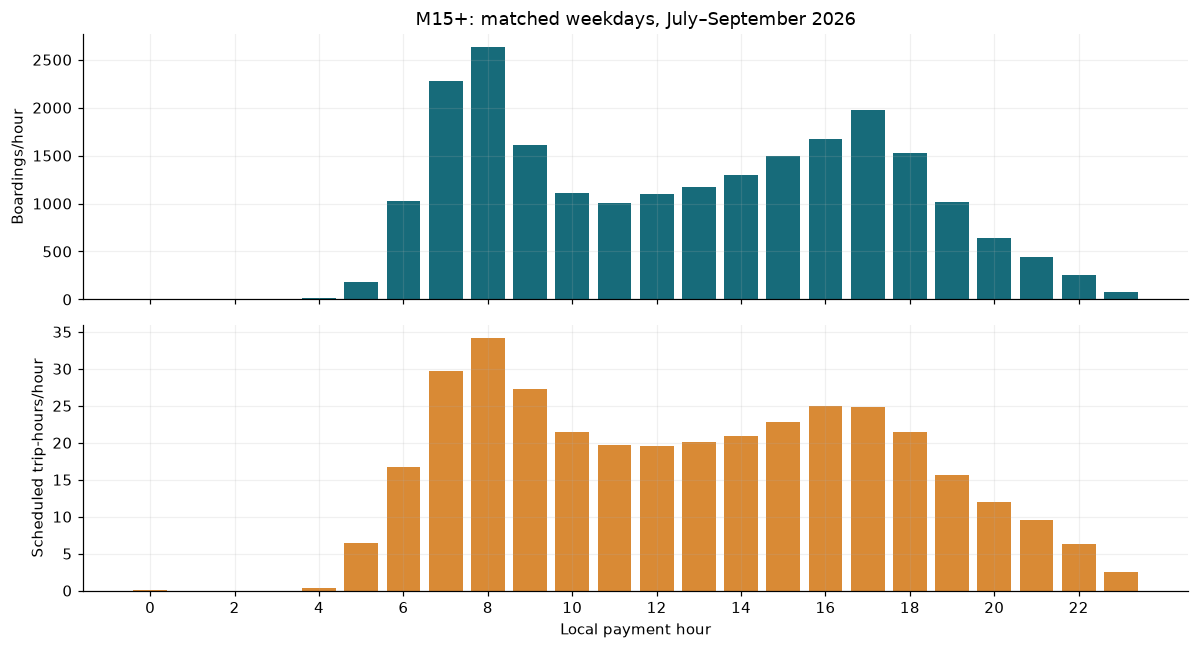

,mean_boardings,mean_scheduled_hours,mean_departures,dates
hour,,,,
0,3.343750,0.039062,0.000000,64
1,1.593750,0.000000,0.000000,64
2,0.421875,0.000000,0.000000,64
3,0.484375,0.000000,0.000000,64
4,13.171875,0.322917,1.937500,64
5,182.609375,6.474479,13.562500,64
6,1026.203125,16.697396,27.140625,64
7,2280.921875,29.720833,36.015625,64
8,2635.140625,34.169010,32.359375,64


In [8]:
example_route=hours.groupby('bus_route').analysis_boardings.sum().idxmax()
sample=hours.loc[hours.bus_route.eq(example_route)&hours.day_type.eq('Weekday')&hours.comparison_eligible]
hour_comparison=sample.groupby('hour').agg(mean_boardings=('analysis_boardings','mean'),
    mean_scheduled_hours=('scheduled_service_hours','mean'),mean_departures=('scheduled_departures','mean'),dates=('payment_date','nunique'))
fig,axes=plt.subplots(2,1,figsize=(11,6),sharex=True)
axes[0].bar(hour_comparison.index,hour_comparison.mean_boardings,color='#176b7a')
axes[0].set(ylabel='Boardings/hour',title=f'{example_route}: matched weekdays, July–September 2026')
axes[1].bar(hour_comparison.index,hour_comparison.mean_scheduled_hours,color='#d98a35')
axes[1].set(ylabel='Scheduled trip-hours/hour',xlabel='Local payment hour',xticks=range(0,24,2))
finish('06_demand_and_scheduled_service')
display(hour_comparison)

## 8. Which route/day types merit service-use review?

Use total boardings divided by total scheduled hours/departures over the same eligible dates.
Require at least 20 observed dates per route/day type for an illustrative review list. The bottom
10% is a relative descriptive threshold, not an underutilization label or a recommendation to cut service.
Exclusive stops are shown so coverage needs are visible. Population, passenger journeys and costs
would be needed to decide whether a service is inefficient.

,bus_route,day_type,observed_dates,first_date,last_date,boardings_per_scheduled_departure,boardings_per_scheduled_service_hour,exclusive_stop_ids
72,M35,Saturday,33,2026-01-17,2026-09-26,2.756833,11.747375,21
48,M20,Saturday,33,2026-01-17,2026-09-26,13.445102,13.693247,40
87,M55,Saturday,33,2026-01-17,2026-09-26,11.266322,19.039908,28
81,M5,Saturday,33,2026-01-17,2026-09-26,22.463726,19.556892,59
73,M35,Sunday,32,2026-01-18,2026-09-27,1.228894,5.944755,21
49,M20,Sunday,32,2026-01-18,2026-09-27,12.201593,14.415782,40
55,M22,Sunday,32,2026-01-18,2026-09-27,7.248437,17.616456,31
31,M125,Sunday,32,2026-01-18,2026-09-27,9.386084,17.743453,19
74,M35,Weekday,181,2026-01-05,2026-09-30,0.884343,3.884628,21
50,M20,Weekday,181,2026-01-05,2026-09-30,13.857708,13.225291,40


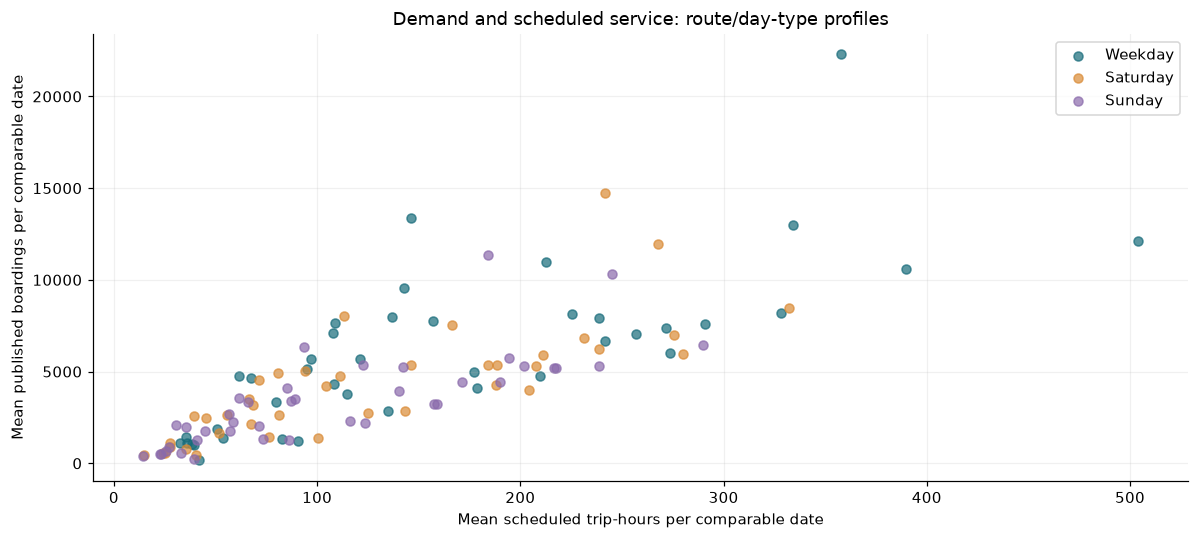

Review candidates: 13 route/day types. These are not operational recommendations.


In [9]:
review=profiles.loc[profiles.enough_dates_for_review].merge(
    structure[['bus_route','served_stop_ids','exclusive_stop_ids']],on='bus_route',validate='many_to_one')
review['day_type_p10']=review.groupby('day_type').boardings_per_scheduled_service_hour.transform(lambda s:s.quantile(.10))
review['low_relative_service_use_review']=review.boardings_per_scheduled_service_hour.le(review.day_type_p10)
review['reason']='Low relative boardings per scheduled hour; coverage and service purpose need review'
shortlist=review.loc[review.low_relative_service_use_review].sort_values(['day_type','boardings_per_scheduled_service_hour'])
display(shortlist[['bus_route','day_type','observed_dates','first_date','last_date',
    'boardings_per_scheduled_departure','boardings_per_scheduled_service_hour','exclusive_stop_ids']])
fig,ax=plt.subplots()
for day_type,color in [('Weekday','#176b7a'),('Saturday','#d98a35'),('Sunday','#8a6aab')]:
    part=review.loc[review.day_type.eq(day_type)]
    ax.scatter(part.total_scheduled_service_hours/part.observed_dates,part.mean_daily_boardings,
               alpha=.7,s=35,label=day_type,color=color)
ax.set(xlabel='Mean scheduled trip-hours per comparable date',ylabel='Mean published boardings per comparable date',
       title='Demand and scheduled service: route/day-type profiles')
ax.legend();finish('07_demand_supply_profiles')
shortlist.to_csv(REPORT/'service_use_review_candidates.csv',index=False)
print('Review candidates:',len(shortlist),'route/day types. These are not operational recommendations.')

## 9. Sensitivity to quality filters and sample requirements

Show how exclusions and thresholds affect conclusions. The inclusive view keeps questionable
published counts, while the conservative view masks them. A route with limited observations
should not appear more certain merely because its ratio is extreme.

In [10]:
sensitivity=[]
schedule_available=matched.loc[matched.schedule_comparison_eligible.astype('boolean').fillna(False)&matched.scheduled_service_hours.gt(0)]
for label,frame,column in [('Inclusive source',schedule_available,'published_boardings'),
                           ('Conservative view',eligible,'analysis_boardings')]:
    sensitivity.append({'view':label,'rows':len(frame),'routes':frame.bus_route.nunique(),
        'boardings_per_scheduled_hour':frame[column].sum()/frame.scheduled_service_hours.sum()})
display(pd.DataFrame(sensitivity))
sample_sensitivity=[]
for minimum in [10,20,30]:
    part=profiles.loc[profiles.observed_dates.ge(minimum)].copy()
    cutoff=part.groupby('day_type').boardings_per_scheduled_service_hour.transform(lambda s:s.quantile(.10))
    sample_sensitivity.append([minimum,len(part),int(part.boardings_per_scheduled_service_hour.le(cutoff).sum())])
display(pd.DataFrame(sample_sensitivity,columns=['minimum_dates','eligible_route_day_types','bottom_decile_review_rows']))

,view,rows,routes,boardings_per_scheduled_hour
0,Inclusive source,10298,41,35.267023
1,Conservative view,10014,41,36.123259


,minimum_dates,eligible_route_day_types,bottom_decile_review_rows
0,10,121,13
1,20,121,13
2,30,121,13


## 10. Geographic density of scheduled access

This historical September snapshot maps **served stops**, not passenger locations. The left
panel bins stop density; the right shows how many distinct Manhattan routes reference each stop.
Coordinates are in longitude/latitude for display only. This is not a population accessibility model
and cannot establish that an unserved area needs a new bus route.

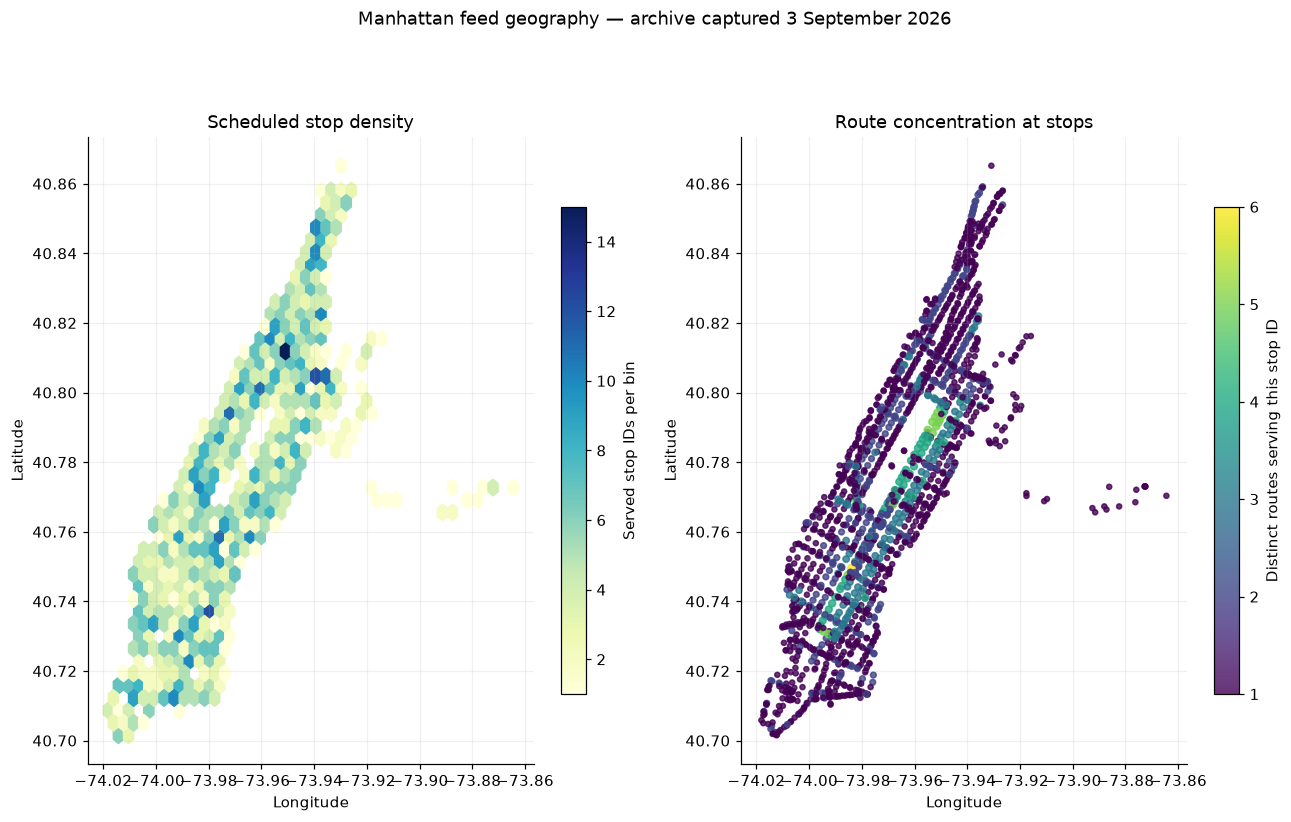

,stop_id,stop_name,routes_serving_stop
159,400323,5 AV/W 36 ST,6
33,400041,MADISON AV/E 98 ST,5
35,400043,MADISON AV/E 102 ST,5
37,400045,MADISON AV/E 106 ST,5
78,400111,5 AV/E 102 ST,5
76,400109,5 AV/E 106 ST,5
77,400110,5 AV/E 104 ST,5
36,400044,MADISON AV/E 104 ST,5
34,400042,MADISON AV/E 101 ST,5
339,400860,BROADWAY/W 61 ST,5


In [11]:
fig,axes=plt.subplots(1,2,figsize=(12,8))
hb=axes[0].hexbin(stops.stop_lon,stops.stop_lat,gridsize=40,mincnt=1,cmap='YlGnBu')
fig.colorbar(hb,ax=axes[0],shrink=.6,label='Served stop IDs per bin')
sc=axes[1].scatter(stops.stop_lon,stops.stop_lat,c=stops.routes_serving_stop,
    s=8+stops.routes_serving_stop*3,cmap='viridis',alpha=.8)
fig.colorbar(sc,ax=axes[1],shrink=.6,label='Distinct routes serving this stop ID')
for ax,title in zip(axes,['Scheduled stop density','Route concentration at stops']):
    ax.set(title=title,xlabel='Longitude',ylabel='Latitude');ax.set_aspect(1/np.cos(np.deg2rad(stops.stop_lat.mean())))
fig.suptitle('Manhattan feed geography — archive captured 3 September 2026')
finish('08_stop_density_and_route_concentration')
display(stops.sort_values('routes_serving_stop',ascending=False)[['stop_id','stop_name','routes_serving_stop']].head(10))

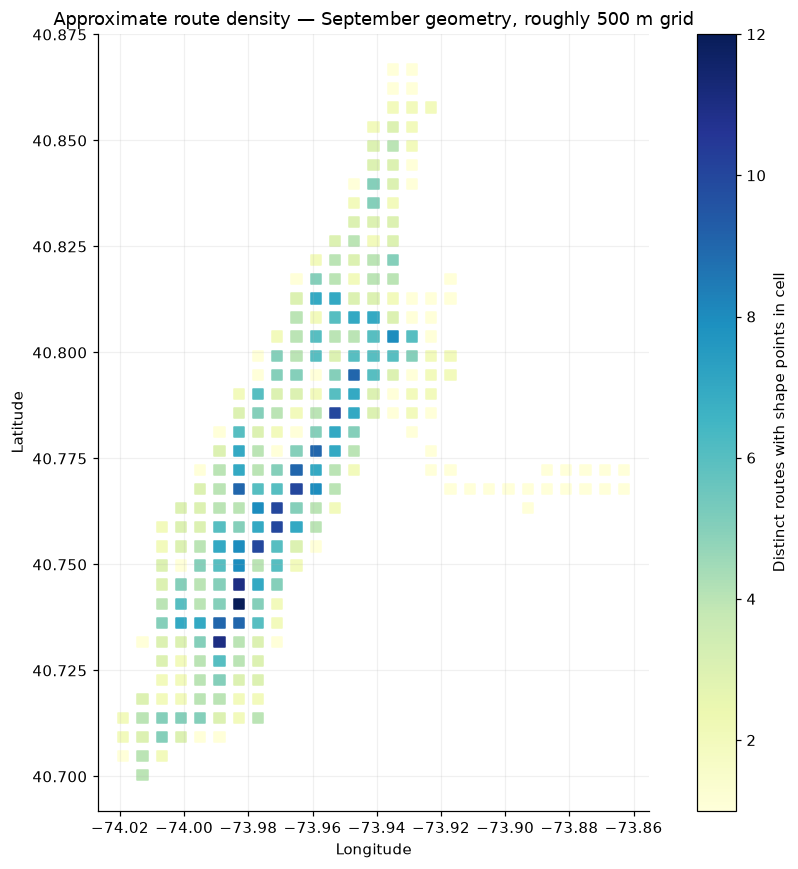

Grid cells represented: 266 ; maximum distinct routes in a cell: 12
Shape-point sampling can miss a crossed cell. This is approximate route density, not passenger density.


In [12]:
# Approximate route density: unique routes with sampled shape points in each ~500 m cell.
geometry_points=shapes.merge(route_shapes,on='shape_id',validate='many_to_many')
geometry_points['longitude_bin']=np.floor(geometry_points.shape_pt_lon/0.006).astype(int)
geometry_points['latitude_bin']=np.floor(geometry_points.shape_pt_lat/0.0045).astype(int)
route_density=geometry_points.groupby(['longitude_bin','latitude_bin']).bus_route.nunique().rename('distinct_routes').reset_index()
fig,ax=plt.subplots(figsize=(9,8))
sc=ax.scatter((route_density.longitude_bin+.5)*.006,(route_density.latitude_bin+.5)*.0045,
    c=route_density.distinct_routes,s=45,marker='s',cmap='YlGnBu')
fig.colorbar(sc,ax=ax,label='Distinct routes with shape points in cell')
ax.set(title='Approximate route density — September geometry, roughly 500 m grid',xlabel='Longitude',ylabel='Latitude')
ax.set_aspect(1/np.cos(np.deg2rad(stops.stop_lat.mean())))
finish('12_route_geometry_density')
route_density.to_csv(REPORT/'route_geometry_density.csv',index=False)
print('Grid cells represented:',len(route_density),'; maximum distinct routes in a cell:',route_density.distinct_routes.max())
print('Shape-point sampling can miss a crossed cell. This is approximate route density, not passenger density.')

## 11. Route overlap and exclusive coverage

The matrix uses shared stop IDs within one archive. Blank diagonal cells are self-comparisons.
The route-pair map below uses the strongest non-self Jaccard pair; distinct branches and terminal
coverage must be reviewed before any merge scenario. Common stops may be valuable transfer points.

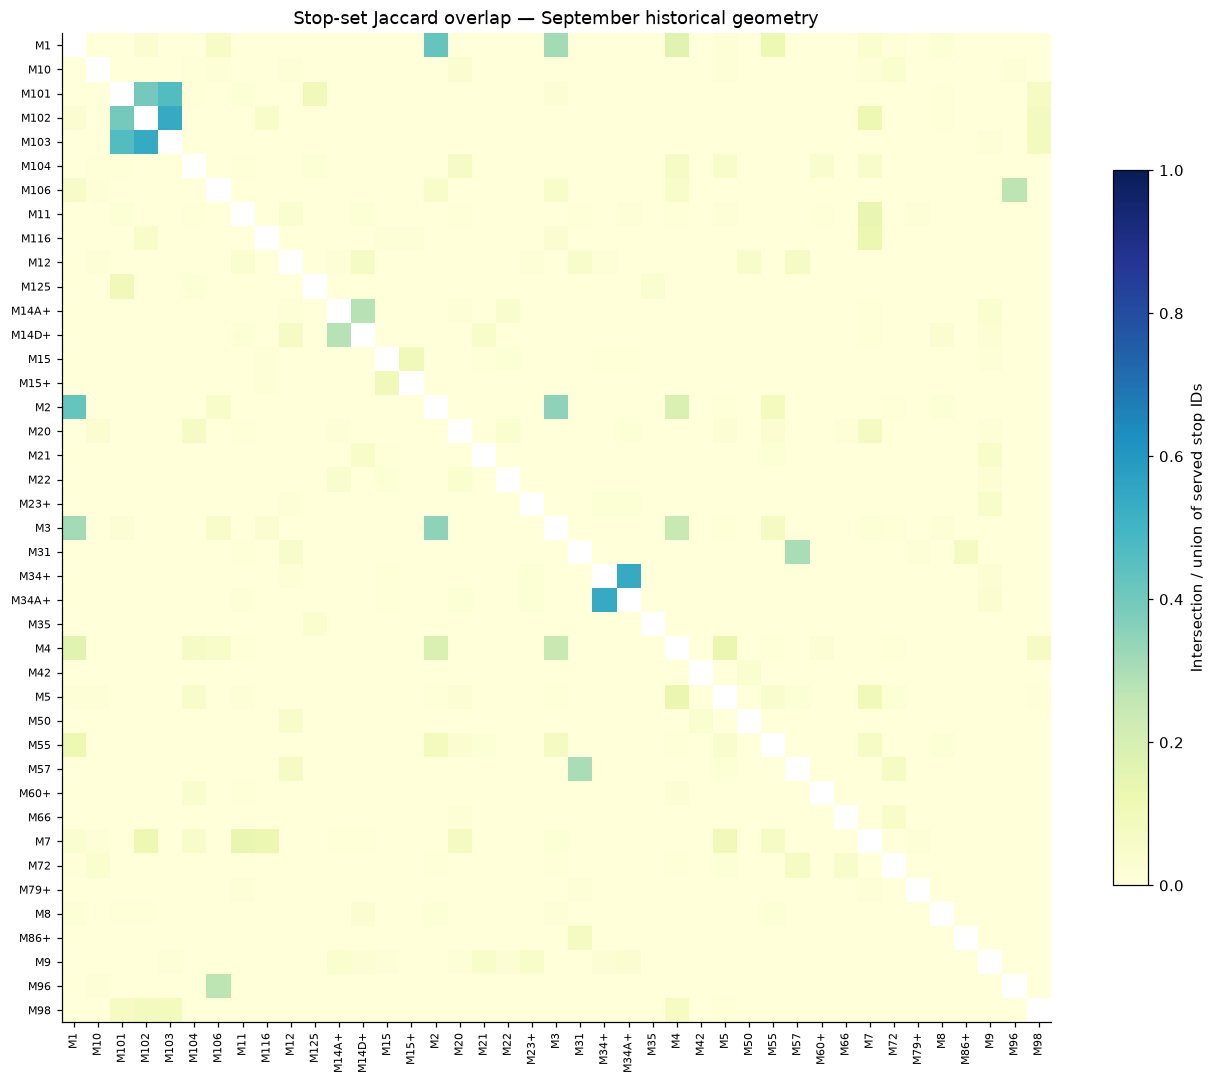

,route_a,route_b,shared_stop_ids,jaccard,smaller_route_overlap,a_only_stop_ids,b_only_stop_ids,snapshot_id
649,M34+,M34A+,22,0.536585,0.758621,12,7,manhattan_20260903
117,M102,M103,76,0.535211,0.723810,37,29,manhattan_20260903
80,M101,M103,81,0.462857,0.771429,70,24,manhattan_20260903
14,M1,M2,83,0.425641,0.619403,51,61,manhattan_20260903
79,M101,M102,75,0.396825,0.663717,76,38,manhattan_20260903
499,M2,M3,79,0.348018,0.548611,65,83,manhattan_20260903
19,M1,M3,70,0.309735,0.522388,64,92,manhattan_20260903
638,M31,M57,23,0.302632,0.547619,34,19,manhattan_20260903
385,M14A+,M14D+,19,0.279412,0.452381,23,26,manhattan_20260903
257,M106,M96,12,0.266667,0.500000,21,12,manhattan_20260903


Pairs sharing at least one stop: 128 of 820


In [13]:
matrix=pd.DataFrame(np.nan,index=pilot_routes,columns=pilot_routes)
for row in overlap.itertuples(index=False):
    matrix.loc[row.route_a,row.route_b]=row.jaccard
    matrix.loc[row.route_b,row.route_a]=row.jaccard
fig,ax=plt.subplots(figsize=(12,10))
im=ax.imshow(matrix,cmap='YlGnBu',vmin=0,vmax=1)
ax.set(xticks=range(len(matrix)),xticklabels=matrix.columns,yticks=range(len(matrix)),yticklabels=matrix.index,
       title='Stop-set Jaccard overlap — September historical geometry')
ax.tick_params(axis='x',rotation=90,labelsize=7);ax.tick_params(axis='y',labelsize=7);ax.grid(False)
fig.colorbar(im,ax=ax,label='Intersection / union of served stop IDs',shrink=.7)
finish('09_route_overlap_matrix')
top_pairs=overlap.sort_values(['jaccard','shared_stop_ids'],ascending=False).head(10)
display(top_pairs)
print('Pairs sharing at least one stop:',int(overlap.shared_stop_ids.gt(0).sum()),'of',len(overlap))

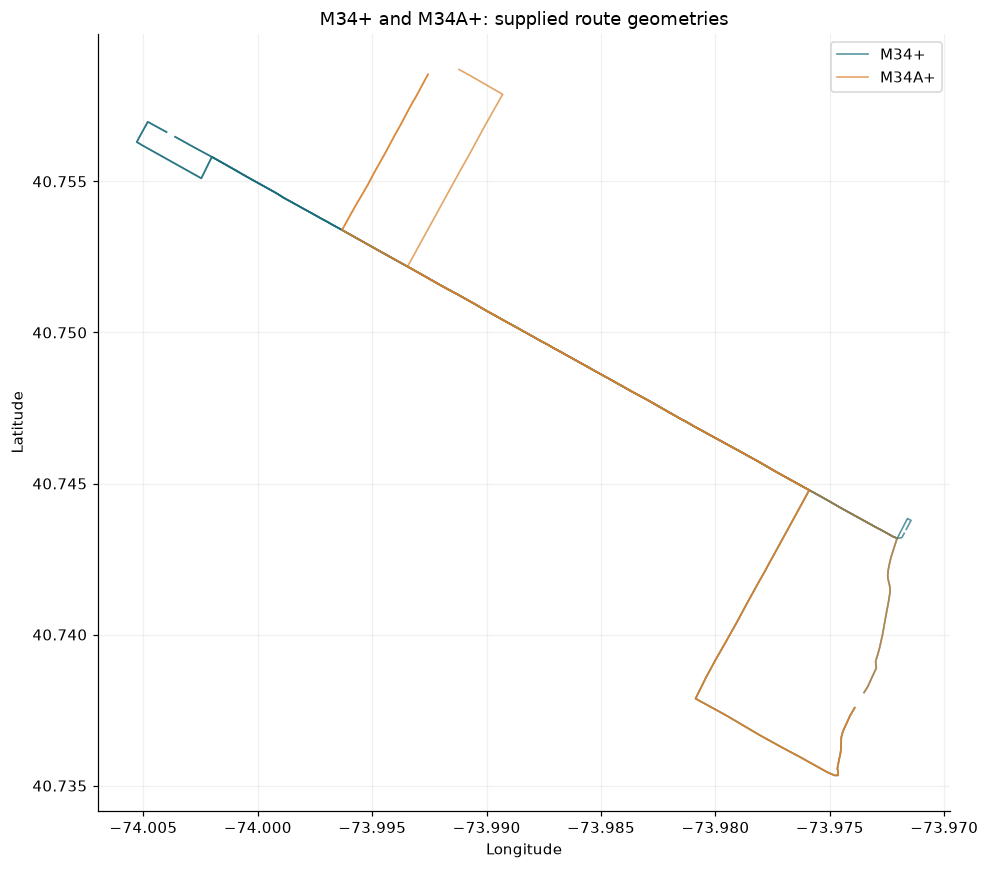

,bus_route,served_stop_ids,exclusive_stop_ids,stop_patterns,snapshot_id
22,M34+,34,11,4,manhattan_20260903
23,M34A+,29,3,2,manhattan_20260903


This pair is a corridor-review example. No merge or passenger benefit is inferred.


In [14]:
pair=top_pairs.iloc[0]
fig,ax=plt.subplots(figsize=(9,8))
for route,color in [(pair.route_a,'#176b7a'),(pair.route_b,'#d97f28')]:
    ids=set(route_shapes.loc[route_shapes.bus_route.eq(route),'shape_id'])
    first=True
    for shape_id,line in shapes.loc[shapes.shape_id.isin(ids)].groupby('shape_id'):
        line=line.sort_values('shape_pt_sequence')
        ax.plot(line.shape_pt_lon,line.shape_pt_lat,color=color,lw=1.1,alpha=.7,label=route if first else None)
        first=False
ax.set(title=f'{pair.route_a} and {pair.route_b}: supplied route geometries',xlabel='Longitude',ylabel='Latitude')
ax.set_aspect(1/np.cos(np.deg2rad(stops.stop_lat.mean())));ax.legend()
finish('10_example_overlap_geometry')
display(structure.loc[structure.bus_route.isin([pair.route_a,pair.route_b]),
    ['bus_route','served_stop_ids','exclusive_stop_ids','stop_patterns','snapshot_id']])
print('This pair is a corridor-review example. No merge or passenger benefit is inferred.')

## 12. Inspect relationships and unusual demand before modelling

These 41 route profiles are a small structural sample. Correlations are descriptive and may reflect
service design, not causation. Features derived from the same numerator/denominator can be
redundant; do not turn service-use ratios into predictors for their own boarding target.

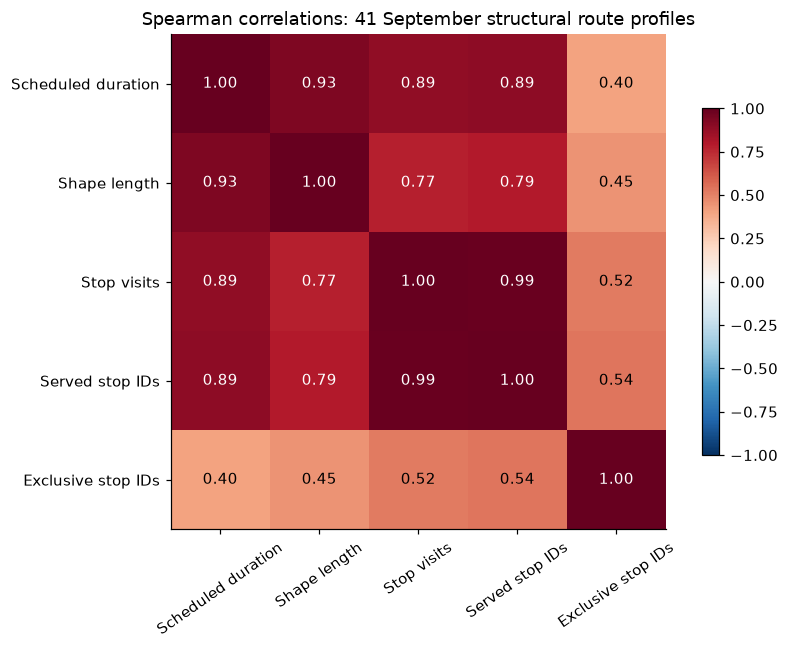

,mean_template_duration_minutes,mean_template_shape_length_km,mean_template_stop_visits,served_stop_ids,exclusive_stop_ids
count,41.00,41.00,41.00,41.00,41.00
mean,44.76,7.88,30.89,66.32,29.68
std,23.46,4.28,18.19,43.25,20.53
min,13.47,2.99,11.50,23.00,1.00
25%,24.10,4.04,16.50,34.00,16.00
50%,35.78,5.56,21.00,42.00,26.00
75%,68.33,12.46,51.31,105.00,36.00
max,93.15,15.51,70.40,162.00,101.00


In [15]:
cols=['mean_template_duration_minutes','mean_template_shape_length_km','mean_template_stop_visits','served_stop_ids','exclusive_stop_ids']
corr=structure[cols].corr(method='spearman')
labels=['Scheduled duration','Shape length','Stop visits','Served stop IDs','Exclusive stop IDs']
fig,ax=plt.subplots(figsize=(8,6))
im=ax.imshow(corr,vmin=-1,vmax=1,cmap='RdBu_r')
for i in range(len(cols)):
    for j in range(len(cols)): ax.text(j,i,f'{corr.iloc[i,j]:.2f}',ha='center',va='center',
        color='white' if abs(corr.iloc[i,j])>.7 else 'black')
ax.set(xticks=range(len(cols)),xticklabels=labels,yticks=range(len(cols)),yticklabels=labels,
       title='Spearman correlations: 41 September structural route profiles')
ax.tick_params(axis='x',rotation=35);ax.grid(False);fig.colorbar(im,ax=ax,shrink=.7)
finish('11_structural_feature_correlations')
display(structure[cols].describe().round(2))

In [16]:
# Retrospective unusual-value screen: not a model input or automatic deletion rule.
group_keys=['bus_route','day_type','hour']
stats=hours.groupby(group_keys).ridership.agg(q25=lambda s:s.quantile(.25),q75=lambda s:s.quantile(.75),samples='size').reset_index()
screen=hours[['bus_route','payment_date','day_type','hour','ridership']].merge(stats,on=group_keys,validate='many_to_one')
screen['upper_review_threshold']=screen.q75+3*(screen.q75-screen.q25)
screen['high_value_review']=screen.samples.ge(8)&screen.ridership.gt(screen.upper_review_threshold)&screen.ridership.gt(0)
unusual=screen.loc[screen.high_value_review].sort_values('ridership',ascending=False)
display(unusual[['bus_route','payment_date','hour','ridership','upper_review_threshold','samples']].head(12))
unusual.to_csv(REPORT/'unusual_hourly_demand_review.csv',index=False)
print('Flagged high route-hours:',len(unusual),'; retained unchanged pending source/event investigation.')

,bus_route,payment_date,hour,ridership,upper_review_threshold,samples
18300,M15+,2026-07-19,14,1874,1872.00,13
77076,M86+,2026-09-17,7,1626,1572.50,66
70188,M86+,2026-09-10,7,1573,1572.50,66
77041,M101,2026-09-17,7,1441,1395.75,66
76080,M4,2026-09-16,7,1206,1163.00,66
75084,M15,2026-09-15,7,1183,1153.50,66
70176,M4,2026-09-10,7,1167,1163.00,66
82982,M96,2026-09-23,7,1096,1050.00,66
88886,M96,2026-09-29,7,1067,1050.00,66
73526,M15,2026-09-13,17,1066,1007.00,13


Flagged high route-hours: 645 ; retained unchanged pending source/event investigation.


## 13. Findings, limits and the next decision

The tables below summarize reproducible observations rather than operational prescriptions.
This completes the analysis through EDA. Scaling, chronological model partitions,
baselines, clustering, forecasting, scenarios and the Streamlit interface belong to later stages.

In [17]:
findings=pd.DataFrame([
    ['Scope',f'{len(pilot_routes)} historical Manhattan route codes; full demand history retained','Historical Manhattan schedule network; broader New York demand context'],
    ['Compatible daily comparisons',f'{len(eligible):,} positive-service route/dates over {eligible.payment_date.nunique()} dates','Selected calendar, clock-date integration and demand review applied'],
    ['Hourly demand',f'{hours.payment_date.nunique()} observed dates in July–September 2026','No invented hourly allocation or direction-level demand'],
    ['Weekday peak',f"{int(peaks.loc[peaks.day_type.eq('Weekday'),'hour'].iloc[0]):02d}:00 local median peak",'Boardings, not occupancy'],
    ['Shared corridors',f'{int(overlap.shared_stop_ids.gt(0).sum())} route pairs share stop IDs','Transfer value and exclusive coverage remain unmeasured'],
    ['Review priorities',f'{len(shortlist)} route/day-type relative service-use candidates','At least 20 dates; 10th percentile is an exploratory threshold'],
    ['Quality',f'{int(network.review.sum())} network dates require demand review', 'No cause or correction fabricated'],
    ['Later forecasting','Exact-date lags prepared','Publication timing and route history are unresolved operational gates'],
    ['Unavailable outcomes','Occupancy, actual delay, passenger destinations, realized savings','No classifier labels or causal optimization claim']
],columns=['topic','observed_result','interpretation_or_limit'])
display(findings)
findings.to_csv(REPORT/'findings.csv',index=False)
summary={'scope':'Historical Manhattan bus demand and service EDA',
    'daily_rows':len(daily),'pilot_routes':len(pilot_routes),'comparable_daily_rows':len(eligible),
    'comparable_daily_dates':int(eligible.payment_date.nunique()),
    'hourly_rows':len(hours),'hourly_dates':int(hours.payment_date.nunique()),
    'comparable_hourly_rows':int(hours.comparison_eligible.sum()),
    'overlap_pairs':len(overlap),'pairs_with_shared_stops':int(overlap.shared_stop_ids.gt(0).sum()),
    'service_use_review_rows':len(shortlist),'unusual_hourly_review_rows':len(unusual),
    'figures':[p.name for p in sorted(FIGURES.glob('*.png'))],
    'model_trained':False,'operational_optimization_validated':False}
(REPORT/'eda_summary.json').write_text(json.dumps(summary,indent=2),encoding='utf-8')
clean_manifest=json.loads((OUT/'cleaning_manifest.json').read_text())
for item in clean_manifest['source_files']:
    with (ROOT/item['file']).open('rb') as handle:
        assert hashlib.file_digest(handle,'sha256').hexdigest()==item['sha256']
print('All original source bytes are unchanged. Saved figures:',len(summary['figures']))
print('EDA tables, figures and findings saved.')

,topic,observed_result,interpretation_or_limit
0,Scope,41 historical Manhattan route codes; full dema...,Historical Manhattan schedule network; broader...
1,Compatible daily comparisons,"10,014 positive-service route/dates over 246 d...","Selected calendar, clock-date integration and ..."
2,Hourly demand,92 observed dates in July–September 2026,No invented hourly allocation or direction-lev...
3,Weekday peak,08:00 local median peak,"Boardings, not occupancy"
4,Shared corridors,128 route pairs share stop IDs,Transfer value and exclusive coverage remain u...
5,Review priorities,13 route/day-type relative service-use candidates,At least 20 dates; 10th percentile is an explo...
6,Quality,7 network dates require demand review,No cause or correction fabricated
7,Later forecasting,Exact-date lags prepared,Publication timing and route history are unres...
8,Unavailable outcomes,"Occupancy, actual delay, passenger destination...",No classifier labels or causal optimization claim


All original source bytes are unchanged. Saved figures: 12
EDA tables, figures and findings saved.
